In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df=pd.read_csv("/content/drive/MyDrive/Entri/DATA/social_media_engagement_5000.csv")

In [5]:
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [6]:
df.shape

(5000, 19)

In [7]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   object 
 3   country           5000 non-null   object 
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   object 
 6   post_category     5000 non-null   object 
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   object 
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   object 
 16  sentiment         4850 non-null   object 


In [9]:
df["posted_at"]=pd.to_datetime(df["posted_at"],format="%d-%m-%Y", errors="coerce")

changed the "posted_at" object datatype to date time data type

In [10]:
df["age"]=df["age"].astype("Int64")
df["likes"]=df["likes"].astype("Int64")
df["comments"]=df["comments"].astype("Int64")
df["shares"]=df["shares"].astype("Int64")

changed the datatypes of age,likes,shares and comments to integer data type

In [11]:
df.dtypes

,0
user_id,int64
age,Int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,Int64
comments,Int64
shares,Int64


In [12]:
df.isnull().sum()

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


it is show that almost 150 data have null value of 150 in likes,comments,shares,age,gender and sentiment.
these can be filled with mean,median and mode accordingly

In [13]:
age_median=df["age"].median()
likes_median=df["likes"].median()
comments_median=df["comments"].median()
shares_median=df["shares"].median()
gender_mode=df["gender"].mode()[0]
sentiment_mode=df["sentiment"].mode()[0]

In [14]:
print(age_median,likes_median,comments_median,shares_median,gender_mode,sentiment_mode)

38.0 10105.5 1497.0 1012.0 Male positive


found out the misisng values of age,likes,comment,shares,gender,sentiment with median and mode

In [15]:
df["age"].fillna(age_median,inplace=True)
df["likes"].fillna(10106,inplace=True)
df["comments"].fillna(comments_median,inplace=True)
df["shares"].fillna(shares_median,inplace=True)

/tmp/ipykernel_2251/989168110.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["age"].fillna(age_median,inplace=True)
/tmp/ipykernel_2251/989168110.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df

filled null value with median

In [16]:
df["gender"].fillna(gender_mode,inplace=True)
df["sentiment"].fillna(sentiment_mode,inplace=True)

/tmp/ipykernel_2251/760249195.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["gender"].fillna(gender_mode,inplace=True)
/tmp/ipykernel_2251/760249195.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using

filled null value with mode

In [17]:
df.duplicated(["post_id","user_id"]).sum()

np.int64(0)

Understood that there is no duplicated having the same "post_id" and "user_id"

In [18]:
print(df["post_id"].duplicated().sum())

9


In [19]:
print(df["user_id"].duplicated().sum())

138


In [20]:
duplicates=df[df["post_id"].duplicated(keep=False)].sort_values("post_id")
print(duplicates[["post_id","user_id","likes","comments","shares"]])

      post_id  user_id  likes  comments  shares
3941   301157    73811  13388       995      69
3336   301157    82127   9512      2814    1019
2153   444417    59104  16786       227    1080
4993   444417    82779  19664      2695    1530
2117   448492    69189    790      1794    1684
693    448492    15713  12383      1519      93
4888   457659    22453  13507      2445    1526
4773   457659    29288   6480      1877    1788
3791   671719    92152  10106       945    1067
204    671719    73734   8653      2407     724
1732   778627    38541   9096      1553       1
560    778627    61934  19857       958    1190
3477   884118    78026   8105      1458     879
1221   884118    44911   8921       980     156
970    911399    49809   3694       915     336
1955   911399    38404   8849      1714    1305
4211   973523    65312  13201      2554    1033
1304   973523    84182  19307      1449     519


Found out there are duplicate post id so removing the duplicate for more precise data
9 rows are removed

In [21]:
df=df.drop_duplicates(subset=["post_id"],keep="first")

In [22]:
df.shape

(4991, 19)

In [23]:
df["post_id"].duplicated().sum()

np.int64(0)

In [24]:
df.isna().sum()

,0
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


In [25]:
df["gender"].value_counts()

,count
gender,
Male,1842
Other,1581
Female,1568


In [26]:
df["sentiment"].value_counts()

,count
sentiment,
positive,2508
neutral,1525
negative,958


In [27]:
df.describe()


,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate
count,4991.000000,4991.0,4991.000000,4991.0,4991.0,4991.0,4991.000000,4991.000000,4991,4991.000000,4991.000000
mean,54547.943699,38.439591,547854.825486,10105.861751,1501.511921,1002.897015,4015.120617,50029.706872,2022-12-28 10:38:12.286115072,393904.683631,0.964971
min,10055.000000,13.0,100068.000000,10.0,0.0,0.0,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363
25%,32281.000000,26.0,322410.000000,5224.5,791.0,511.0,2023.500000,24997.000000,2022-07-03 12:00:00,195064.500000,0.145709
50%,54327.000000,38.0,547905.000000,10106.0,1497.0,1012.0,4034.000000,49954.000000,2022-12-27 00:00:00,389040.000000,0.253806
75%,77172.500000,51.0,771256.500000,14965.0,2234.5,1482.5,6020.500000,74715.500000,2023-06-27 12:00:00,589869.000000,0.504695
max,99963.000000,64.0,999455.000000,19998.0,2999.0,1999.0,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348
std,26094.658996,14.686923,260657.341322,5703.628073,856.683226,570.842898,2307.053146,28845.669265,NaN,230898.849565,5.322732


In [28]:
print("Comments > impressions:", (df["comments"] > df["impression_count"]).sum())
print("Shares > impressions:", (df["shares"] > df["impression_count"]).sum())
print("Watch time max:", df["watch_time_sec"].max())

Comments > impressions: 65
Shares > impressions: 55
Watch time max: 7998


we found out that there are impressions more than comments which is realistically not possible,
there are 65 comments and 55 share more than impression count of the post so we remove them almost 2.4 % of the rows

In [29]:
df=df[(df["comments"]<= df["impression_count"]) & (df["shares"]<= df["impression_count"])]
df.shape

(4910, 19)

In [30]:
print(df['hashtags'].str.count("#").sum())

9819


we found that there are count of 9819 hashtags(#) on the data
almost 100% more than the row counts

In [31]:
label_cols=["gender","post_type","post_category","country","device_type","sentiment"]
for col in label_cols:
  df[col]=df[col].str.strip().str.lower()

Standardized every labels in the data and removed unwanted spaces

In [32]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,female,brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33,male,brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32,female,uk,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51,other,france,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34,other,uk,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372


In [33]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44,male,australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38,other,uae,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63,female,usa,273595,text,travel,13487,1497,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13,female,germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518
4999,73400,54,other,japan,712252,text,travel,14830,503,1798,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527


In [34]:
df.shape

(4910, 19)

In [35]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

In [36]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4910 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           4910 non-null   int64         
 1   age               4910 non-null   Int64         
 2   gender            4910 non-null   object        
 3   country           4910 non-null   object        
 4   post_id           4910 non-null   int64         
 5   post_type         4910 non-null   object        
 6   post_category     4910 non-null   object        
 7   likes             4910 non-null   Int64         
 8   comments          4910 non-null   Int64         
 9   shares            4910 non-null   Int64         
 10  watch_time_sec    4910 non-null   int64         
 11  impression_count  4910 non-null   int64         
 12  posted_at         4910 non-null   datetime64[ns]
 13  follower_count    4910 non-null   int64         
 14  is_verified       4910 non-nu

In [37]:
df.dtypes

,0
user_id,int64
age,Int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,Int64
comments,Int64
shares,Int64


In [38]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate
count,4910.000000,4910.0,4910.000000,4910.0,4910.0,4910.0,4910.000000,4910.000000,4910,4910.000000,4910.000000
mean,54624.992261,38.408147,547650.685947,10082.188798,1500.397556,1001.20224,4017.571283,50840.261303,2022-12-28 00:57:11.364562176,394130.624033,0.517253
min,10055.000000,13.0,100184.000000,10.0,0.0,0.0,0.000000,703.000000,2022-01-01 00:00:00,87.000000,0.006363
25%,32351.000000,26.0,322264.250000,5198.5,791.0,510.0,2018.500000,26259.500000,2022-07-03 00:00:00,194405.750000,0.144168
50%,54411.000000,38.0,546708.000000,10106.0,1497.0,1012.0,4034.500000,50586.500000,2022-12-27 00:00:00,389741.000000,0.249275
75%,77252.750000,51.0,771311.250000,14911.0,2234.0,1476.75,6021.000000,75061.000000,2023-06-26 00:00:00,589983.250000,0.481312
max,99963.000000,64.0,999455.000000,19998.0,2999.0,1999.0,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,23.098151
std,26099.632597,14.703521,260775.584435,5693.513077,855.927604,570.318144,2308.418521,28377.894402,NaN,231072.306132,0.990899


* most of the average and median value are almost close ranged

* average likes per videos are 10,000
* the data is well balanced
* engagement rate is right skewed



In [39]:
df.value_counts()

,,,,,,,,,,,,,,,,,,,count
user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,
99963,40,female,uk,508632,image,music,9029,504,1512,3148,87717,2022-08-14,671383,False,mobile,negative,#tech,0.125916,1
10055,43,female,india,879955,reel,education,602,1778,671,3647,91730,2023-09-04,383072,False,desktop,neutral,#love #fashion,0.033261,1
10060,38,female,uk,814952,video,education,10106,2584,328,3556,50265,2023-07-06,565357,False,mobile,negative,#travel #fitness #fashion,0.091057,1
10077,23,female,germany,330842,reel,travel,3448,521,1012,1989,18055,2022-06-05,499159,False,tablet,neutral,#tech #reels #love,0.232401,1
10112,13,female,india,469322,text,lifestyle,11925,221,567,7519,19871,2022-03-23,552908,False,desktop,positive,#travel #tech,0.639777,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10235,64,other,australia,256131,image,tech,11957,979,114,2280,96535,2022-01-04,410411,False,mobile,positive,#tech #music #lifestyle,0.135184,1
10207,30,female,germany,752862,video,lifestyle,18148,4,424,3567,20810,2023-06-03,664054,False,desktop,positive,#reels #tech #fitness,0.892648,1
10206,29,other,canada,802551,reel,travel,17842,2853,799,4774,91351,2022-04-17,547686,False,desktop,positive,#fun #music #travel,0.235290,1


In [40]:
print("unique values and counts")
print()
print("post_type:", df["post_type"].value_counts())
print()
print("Country:", df["country"].value_counts())
print()
print("Device type:", df["device_type"].value_counts())
print()


print("Category:", df["post_category"].nunique())
print()
print("Gender:", df["gender"].nunique())
print()
print("Sentiment:", df["sentiment"].nunique())
print()
print("Device type:", df["device_type"].nunique())



unique values and counts

post_type: post_type
reel     1265
image    1226
text     1220
video    1199
Name: count, dtype: int64

Country: country
india        527
canada       505
usa          496
brazil       496
uae          491
uk           486
germany      485
france       482
australia    479
japan        463
Name: count, dtype: int64

Device type: device_type
mobile     1648
tablet     1634
desktop    1628
Name: count, dtype: int64

Category: 8

Gender: 3

Sentiment: 3

Device type: 3


 * all the post type in the data are balanced well
 * Most of the posts are from india
 * all are uploaded from different devices

In [41]:
df.select_dtypes(include=['Int64','float64','int64']).corr()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
user_id,1.000000,-0.006051,0.020737,0.028706,-0.034452,0.016947,-0.019397,0.010599,0.011025,0.005846
age,-0.006051,1.000000,-0.011445,-0.037362,-0.008989,0.011917,0.003459,0.018333,-0.026393,-0.012197
post_id,0.020737,-0.011445,1.000000,0.009745,-0.007432,0.002531,0.017868,-0.006165,-0.004480,0.011626
likes,0.028706,-0.037362,0.009745,1.000000,-0.018481,0.003116,0.008816,0.014718,-0.028386,0.229899
comments,-0.034452,-0.008989,-0.007432,-0.018481,1.000000,0.009263,-0.017861,-0.007424,-0.011570,0.002209
shares,0.016947,0.011917,0.002531,0.003116,0.009263,1.000000,0.015477,0.000360,-0.009997,0.014441
watch_time_sec,-0.019397,0.003459,0.017868,0.008816,-0.017861,0.015477,1.000000,-0.006721,0.005045,0.028894
impression_count,0.010599,0.018333,-0.006165,0.014718,-0.007424,0.000360,-0.006721,1.000000,-0.017467,-0.487733
follower_count,0.011025,-0.026393,-0.004480,-0.028386,-0.011570,-0.009997,0.005045,-0.017467,1.000000,0.006081
engagement_rate,0.005846,-0.012197,0.011626,0.229899,0.002209,0.014441,0.028894,-0.487733,0.006081,1.000000


Post with more likes have slightly higher engagement rate than other 0.23.


The engagement rates are lower than the impression count(-0.49)

In [42]:
df.groupby("post_type")[["likes","engagement_rate","comments"]].mean()

,likes,engagement_rate,comments
post_type,,,
image,10084.446982,0.528241,1524.331974
reel,10046.466403,0.488454,1504.452174
text,10043.834426,0.512955,1495.127869
video,10156.594662,0.540776,1477.00834


* Average rate of likes are in between 10040 - 10160.

* All post types are having similar avg rate of engagement.

* Average rate of comments are between 1477- 1524.




In [43]:
df.groupby("country")[["impression_count","engagement_rate"]].mean()

,impression_count,engagement_rate
country,,
australia,49518.688935,0.578310
brazil,49976.122984,0.478925
canada,49318.948515,0.594753
france,53202.823651,0.505187
germany,49037.890722,0.543572
india,53228.478178,0.438136
japan,50559.311015,0.514233
uae,50011.187373,0.601121
uk,51633.218107,0.455508


In [44]:
df.groupby("sentiment")["engagement_rate"].mean()

,engagement_rate
sentiment,
negative,0.557006
neutral,0.511158
positive,0.505849


Average negative sentiment contents drive more engagement rate than positve and neutral.

Which can mean the contents are more controversial or negatively showing
this can cause negative for the brand to

In [45]:
df.dtypes


,0
user_id,int64
age,Int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,Int64
comments,Int64
shares,Int64


In [46]:
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,female,brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33,male,brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32,female,uk,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51,other,france,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34,other,uk,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44,male,australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38,other,uae,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63,female,usa,273595,text,travel,13487,1497,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13,female,germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [47]:
df["hashtag_count"]= df["hashtags"].str.count("#")

In [48]:
df["engagement_score"] =(df["likes"] * 0.5 + df["comments"] * 1.0 + df["shares"] * 1.5)

The engagement score shows the measure of total interaction by like, share and comment

In [49]:
statistic_cols=["age","likes","comments","shares","watch_time_sec","impression_count","follower_count","engagement_rate","hashtag_count","engagement_score"]

In [50]:
stats=pd.DataFrame({
  "mean":df[statistic_cols].mean(),
  "median":df[statistic_cols].median(),
  "standard deviation":df[statistic_cols].std(),
  "skewness":df[statistic_cols].skew(),
  "kurtosis":df[statistic_cols].kurtosis(),
  "variance":df[statistic_cols].var()
})
print(stats.round(2))

                       mean    median  standard deviation  skewness  kurtosis  \
age                   38.41      38.0                14.7      0.03     -1.13   
likes              10082.19   10106.0             5693.51      -0.0     -1.15   
comments             1500.4    1497.0              855.93      0.01     -1.14   
shares               1001.2    1012.0              570.32     -0.01     -1.15   
watch_time_sec      4017.57    4034.5             2308.42     -0.02      -1.2   
impression_count   50840.26   50586.5            28377.89      0.02      -1.2   
follower_count    394130.62  389741.0           231072.31      0.03     -1.19   
engagement_rate        0.52      0.25                0.99      7.76    100.21   
hashtag_count           2.0       2.0                0.81       0.0     -1.49   
engagement_score     8043.3   7990.75             3083.37      0.01     -0.83   

                            variance  
age                           216.19  
likes                    32416

found out the mean,median,standard deviation,skewness,kurtois,variance of the data

* average age of user is 38
* almost most post crosses 10,000 likes
* but avg 1/10 of people comments and shares
* most post use atleast 2 hashtags for reach
* engagement rate have huge outliers that means some post have huge engagement rate and some have few

In [51]:
df[statistic_cols].mode().iloc[0]

,0
age,38.0
likes,10106.0
comments,1497.0
shares,1012.0
watch_time_sec,916.0
impression_count,24207.0
follower_count,497502.0
engagement_rate,0.006363
hashtag_count,2.0
engagement_score,7286.5


Data Visualization

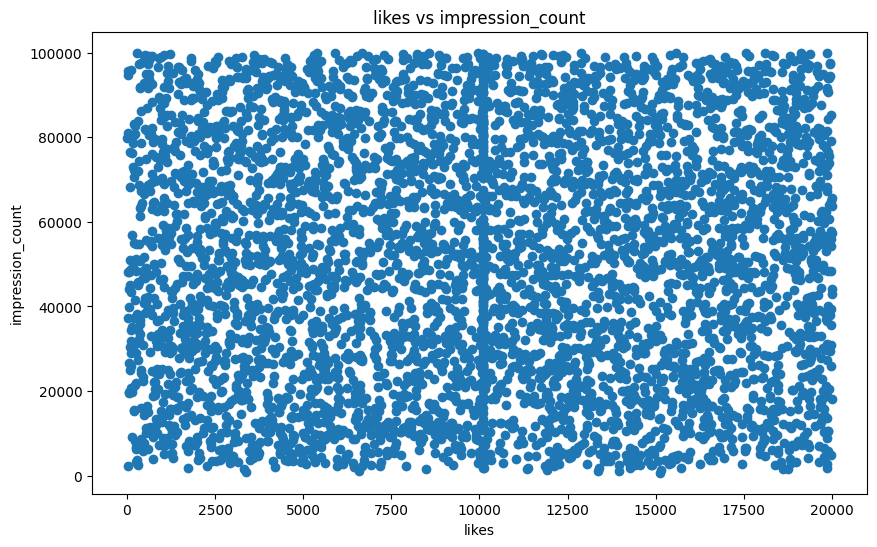

In [52]:
plt.figure(figsize=(10,6))
plt.scatter(df["likes"],df["impression_count"])
plt.xlabel("likes")
plt.ylabel("impression_count")
plt.title("likes vs impression_count")
plt.show()

shows the likes and impression scatters alot but most likes area situated around on 10,000 range


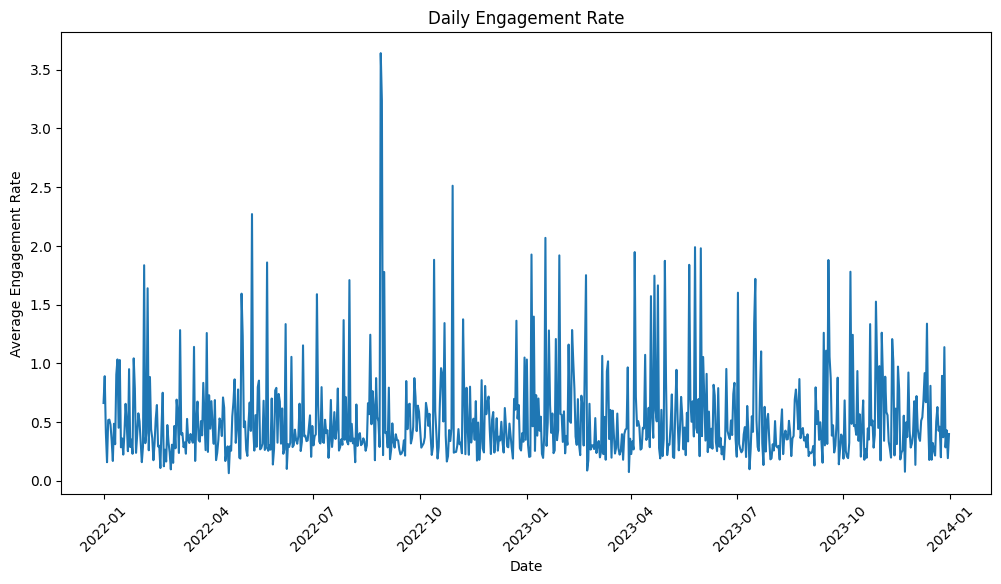

In [53]:
daily_eng=df.groupby(df["posted_at"].dt.date)["engagement_rate"].mean()
plt.figure(figsize=(12,6))
plt.plot(daily_eng.index,daily_eng.values)
plt.xlabel("Date")
plt.ylabel("Average Engagement Rate")
plt.title("Daily Engagement Rate")
plt.xticks(rotation=45)
plt.show()

Here we can see the between july to ocotober 2022
there is a spike in average enagagement rate of about 3.5

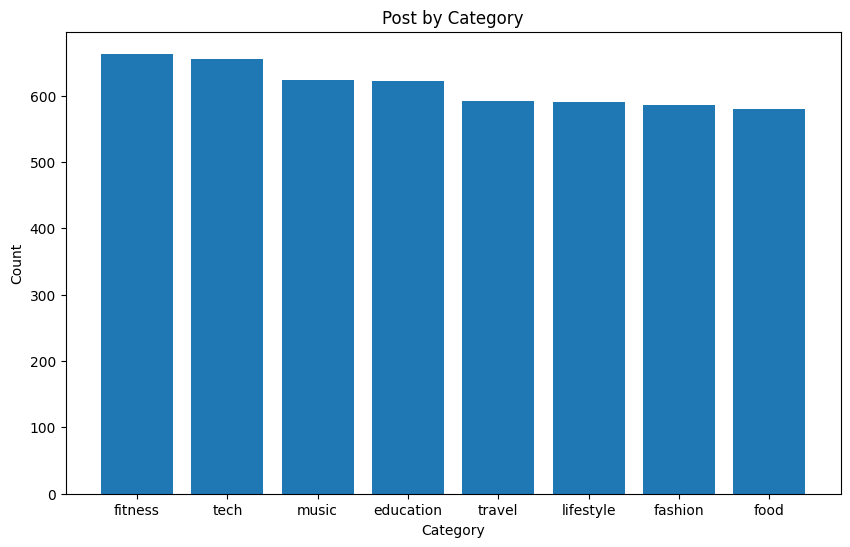

In [54]:
count= df["post_category"].value_counts()

plt.figure(figsize=(10,6))
plt.bar(count.index, count.values)
plt.title("Post by Category")
plt.xlabel("Category")
plt.ylabel("Count")
plt.show()

Shows fitness have higher post counts than any other categories

and tech categories are second and not far from fitness

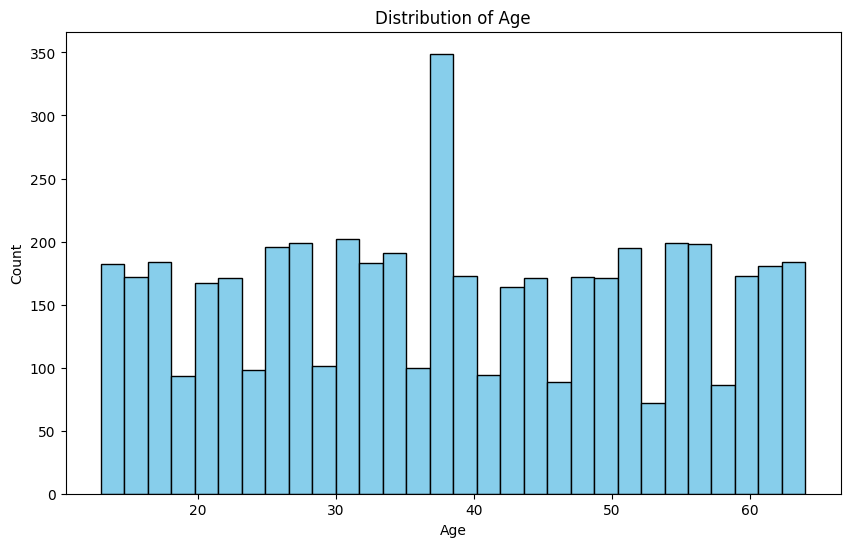

In [55]:
plt.figure(figsize=(10,6))
plt.hist(df["age"],bins=30,color="skyblue",edgecolor="black")
plt.xlabel("Age")
plt.ylabel("Count")
plt.title("Distribution of Age")
plt.show()

show the age between 35 to 40 have the highest distribution rate as users

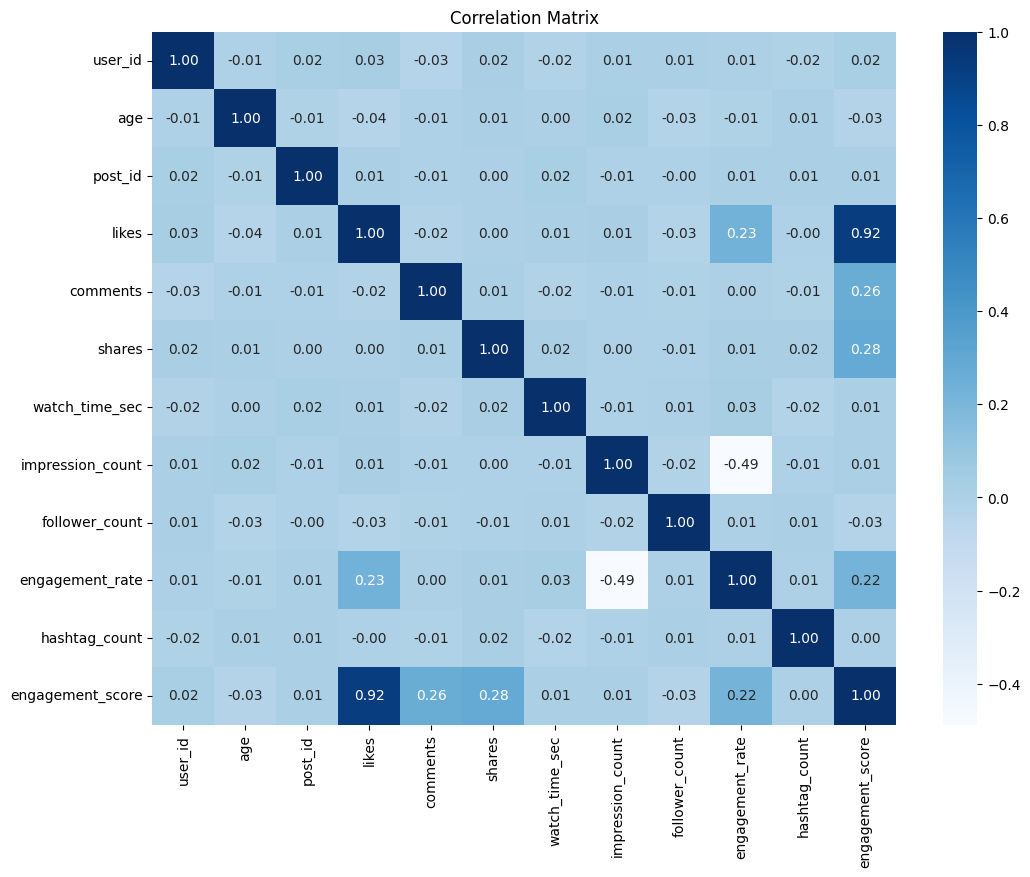

In [56]:
corr_matrix=df.select_dtypes(include=["int64","float64"]).corr()
plt.figure(figsize=(12,9))
sns.heatmap(corr_matrix,fmt=".2f",annot=True,cmap="Blues")
plt.title("Correlation Matrix")
plt.show()

Likes and enagegment score have highest correlation(0.92) than any other inter categories

and enagement rate and impression count have the lowest (-0.49) which shows most contents didnt impressed as expected

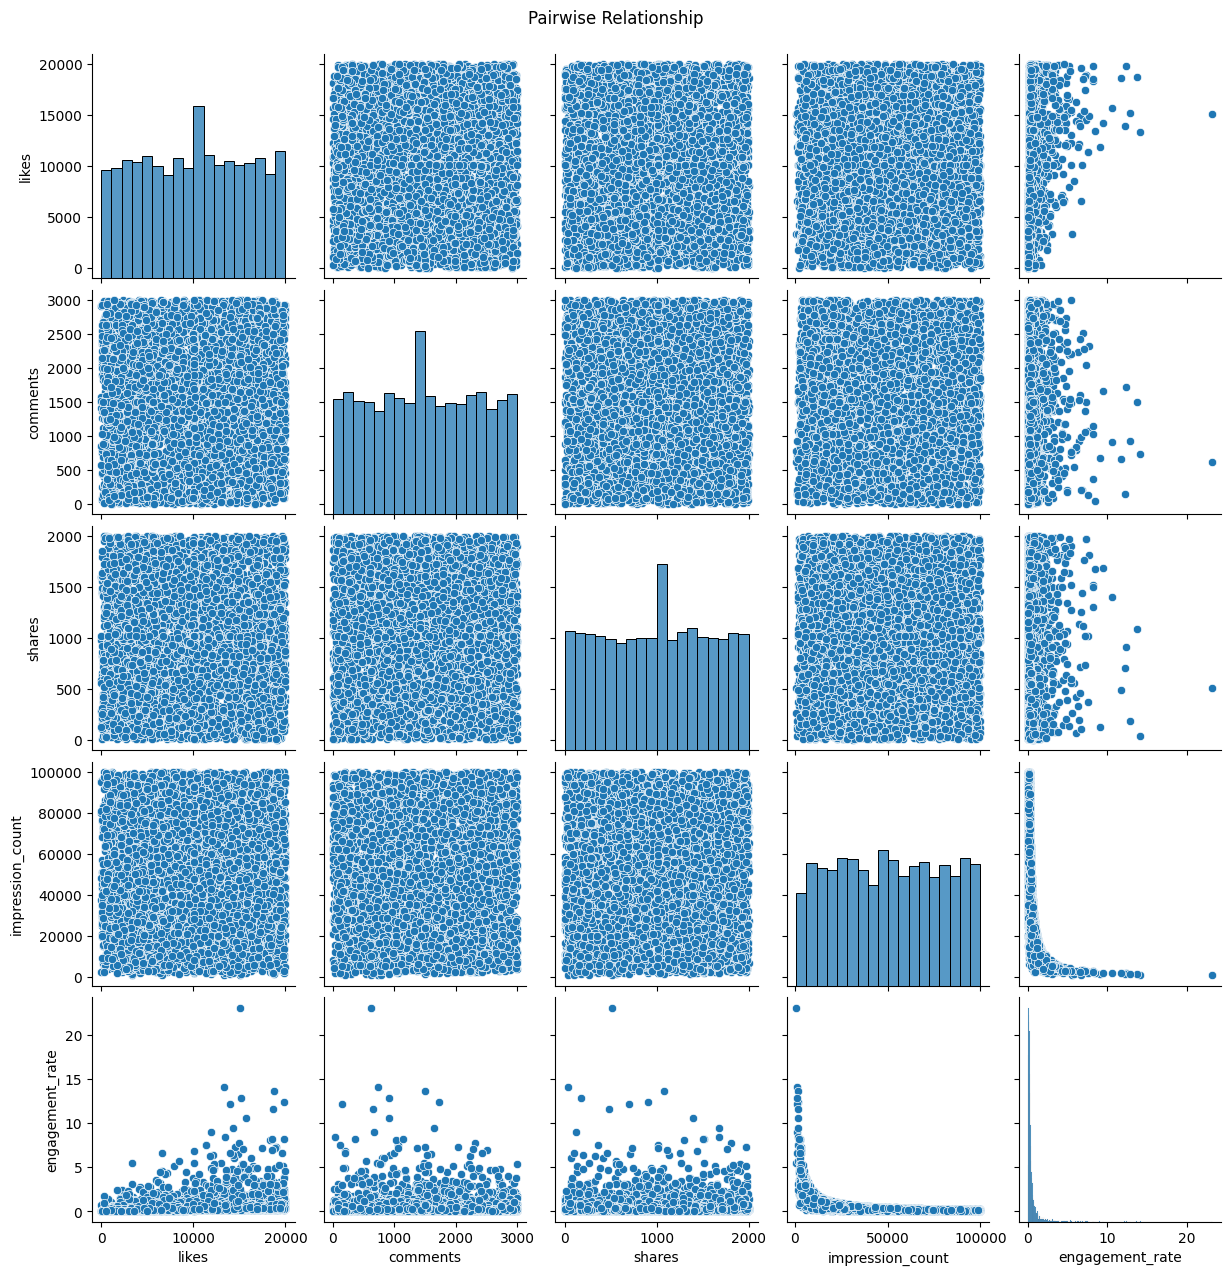

In [57]:
pair_cols=["likes","comments","shares","impression_count","engagement_rate"]

sns.pairplot(df[pair_cols])
plt.suptitle("Pairwise Relationship",y=1.02)
plt.show()

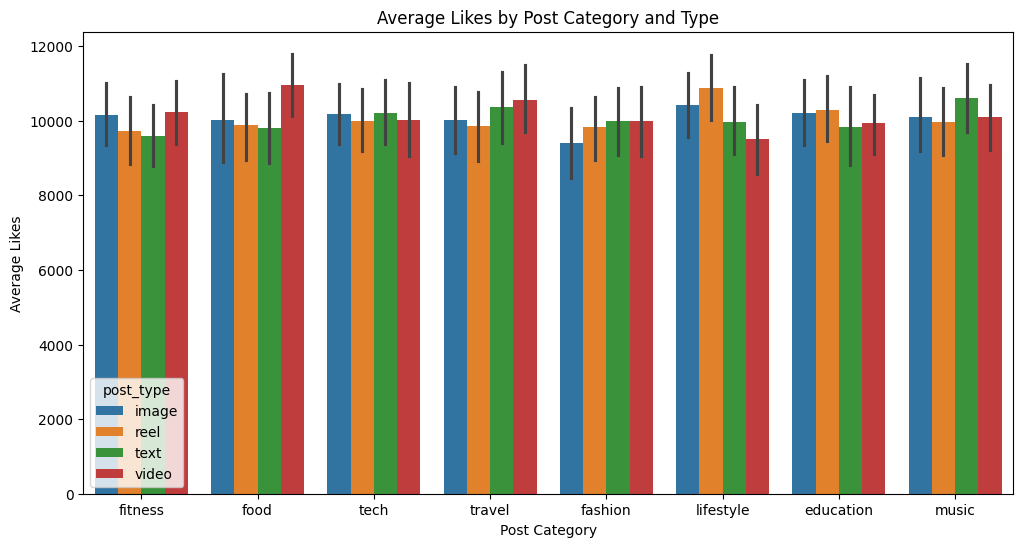

In [58]:
plt.figure(figsize=(12,6))
sns.barplot(data=df,x="post_category",y="likes",estimator="mean",hue="post_type")
plt.xlabel("Post Category")
plt.ylabel("Average Likes")
plt.title("Average Likes by Post Category and Type")
plt.show()

* lifestyle reels and videos from food category is having highest from other categories and post types

    an average of over 10,000+

* second highest are the travel videos and music text

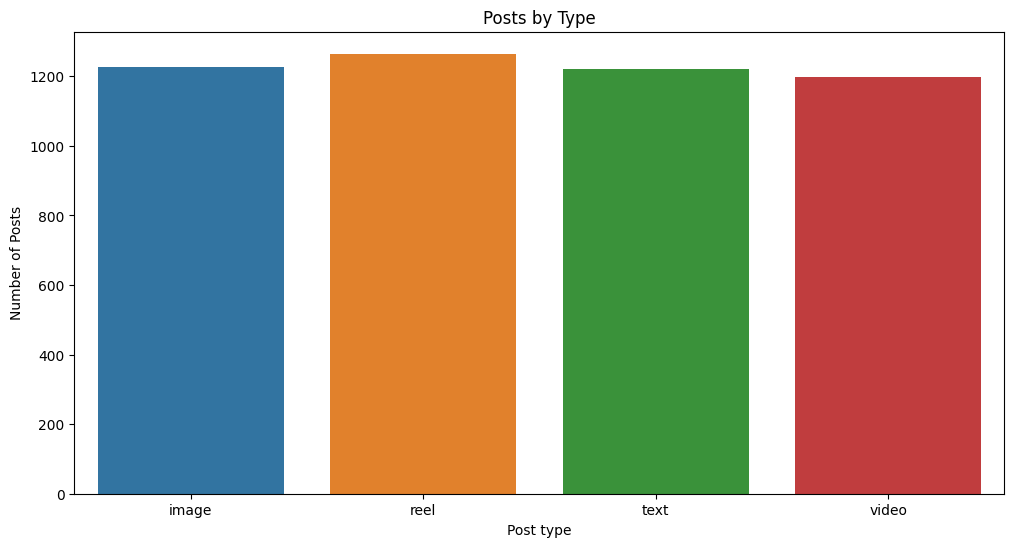

In [59]:
plt.figure(figsize=(12,6))
sns.countplot(data=df,x="post_type",hue="post_type")
plt.xlabel("Post type")
plt.ylabel("Number of Posts")
plt.title("Posts by Type")
plt.show()

Posting count is splitted almost evenly across the formats


In [60]:
import plotly.express as px

In [66]:
daily = df.groupby(df["posted_at"].dt.date)["engagement_score"].mean().reset_index()
daily.columns = ["date", "avg_engagement_score"]

fig = px.line(daily, x="date", y="avg_engagement_score",
              title="Daily Engagement Trend (Interactive)")
fig.show()

The data shows between Dec 18 2022 & Dec 25 2022 have the most avg engagement score

In [69]:
fig2 = px.scatter(df,x="likes",y="impression_count",size="shares",
                  color="post_type",opacity= 0.6,
                  title="bubblechart: Likes vs Impressions"
                  )
fig2.show()

In [71]:
fig3 = px.scatter(df,x="likes",y="impression_count",
                  color="sentiment",opacity= 0.6,
                  title="Scatterchart: Likes vs Impressions"
                  )
fig3.show()

# **Final Insights **

In [74]:
df.groupby("post_type")[["engagement_score","engagement_rate"]].sum()

,engagement_score,engagement_rate
post_type,,
image,9921725.5,647.623919
reel,10123697.5,617.894114
text,9793201.5,625.804599
video,9653955.5,648.390600


In [76]:
df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False)

,engagement_rate
country,
uae,0.601121
canada,0.594753
australia,0.578310
germany,0.543572
japan,0.514233
france,0.505187
brazil,0.478925
usa,0.468061
uk,0.455508


In [77]:
df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 25, 35, 50, 90],
    labels=["18-25", "26-35", "36-50", "51+"]
)

In [80]:
print(df.groupby("age_group", observed=True)[["engagement_rate", "engagement_score"]].mean())
print(df["age_group"].value_counts().sort_index())

           engagement_rate  engagement_score
age_group                                   
18-25             0.505169       8026.839973
26-35             0.525436       8141.493285
36-50             0.506097       8115.829737
51+               0.505936       7816.381599
age_group
18-25     728
26-35     968
36-50    1483
51+      1288
Name: count, dtype: int64


In [81]:
print(df.groupby("is_verified")[["engagement_rate", "engagement_score"]].mean())
print(df["is_verified"].value_counts())

             engagement_rate  engagement_score
is_verified                                   
False               0.518880       8065.696598
True                0.501954       7832.666314
is_verified
False    4438
True      472
Name: count, dtype: int64


In [82]:
print(df["posted_at"].dt.hour.value_counts())

posted_at
0    4910
Name: count, dtype: int64


In [87]:
print(df.groupby("device_type")["watch_time_sec"].mean().sort_values(ascending=False))
print(df["device_type"].value_counts())

device_type
mobile     4093.454490
tablet     3986.552020
desktop    3971.889435
Name: watch_time_sec, dtype: float64
device_type
mobile     1648
tablet     1634
desktop    1628
Name: count, dtype: int64


In [90]:
df.groupby("sentiment")[["engagement_rate", "engagement_score", "likes", "comments", "shares"]].mean().round(3)


,engagement_rate,engagement_score,likes,comments,shares
sentiment,,,,,
negative,0.557,8101.938,10167.739,1509.783,1005.524
neutral,0.511,7986.446,9920.056,1531.031,996.925
positive,0.506,8055.493,10148.008,1478.257,1002.155


In [91]:
df["sentiment"].value_counts()

,count
sentiment,
positive,2472
neutral,1499
negative,939


### Content performance
#### 1. Which post types have highest engagement?



   By using the group by in post types we can see every post type have almost evenly share of engagement and from them we can choose **reels** for the top post type

#### 2.Best-performing content category?
   In the Barplot chart we can identify that both lifestyle and food category have the best performing but in different formats

#### 3.Which countries have highest avg engagement rate?
   UAE shows the highest avg rate of (0.601121) engagement rate than others



### User Trends

#### 1.How age affects engagement
Engagement rate is nearly same across age groups (0.505 to 0.525). Users aged 26-35 show the highest rate, but the gap is small.

#### 2. Performance difference for verified accounts

Verified accounts have a slightly lower average engagement rate (0.502) than non-verified accounts (0.519). The gap is small, and verified accounts make up only about 10% of posts

### Behavioral Insights
#### 1. Best time of day for impressions
posted timings are recorded as dates so we cant anlyze the time of day impressions
#### 2.Device type impact on watch time

Mobile users have highest average watch time (4,093) slightly above tablet(3,987) & desktop(3,972)


### Sentimental Analysis

#### 1.Which sentiment performs best
Negative performs best in engagement rate. It was negative 0.55, neutral 0.51, positive 0.50,
But in overall count positive is the best (positve 2472 ,negative 939 , neutral 1499)
#### 2. Behavior of negative/neutral sentiment posts
Negative post shows the highest engagement rate (0.55)